# Verification of the 2D magnetostatic solver

This notebook imports the repository's shared sparse solver. It checks basic physics, compares a circular cylinder against a closed-form solution, and separates grid refinement from finite-domain sensitivity. The field elements are prescribed for these controlled experiments.

In [1]:
from pathlib import Path
import sys
from time import perf_counter

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "magnetic_model" / "solver.py").is_file())
sys.path.insert(0, str(root))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Markdown, display

from magnetic_model import Grid, OreBody, simulate
from magnetic_model import solver
from magnetic_model.geomagnetic import MU_0, NT_TO_T, survey_field_t
from magnetic_model.geometry import cell_centers
from magnetic_model.observables import air_profile

print("Shared solver:", Path(solver.__file__).resolve().relative_to(root))
print(f"Python {sys.version.split()[0]}, NumPy {np.__version__}, "
      f"SciPy {scipy.__version__}, Matplotlib {matplotlib.__version__}")

Shared solver: magnetic_model/solver.py
Python 3.12.14, NumPy 2.2.6, SciPy 1.15.3, Matplotlib 3.10.3


## 1. Governing equations and numerical method

Magnetostatics gives $\nabla\cdot\mathbf B=0$ and $\nabla\times\mathbf H=\mathbf J_{\rm free}$. With zero free current throughout the domain, the curl-free $\mathbf H$ has a scalar potential on the simply connected model domain. For a linear isotropic medium with no remanence, $\mathbf M=\chi\mathbf H$ and $\mathbf B=\mu_0(\mathbf H+\mathbf M)=\mu_0\mu_r\mathbf H$, with $\mu_r=1+\chi>0$.

Let $x$ point along the survey azimuth $A$, $s$ along strike at azimuth $A+90^\circ$, and $z$ down. For intensity $F$, inclination $I$, and declination $D$, the inducing induction is
$$\mathbf B_0=F(\cos I\cos(D-A),\ \cos I\sin(D-A),\ \sin I).$$
Angles are clockwise from true north for $D,A$, and positive down for $I$. Write $\mathbf H_0=\mathbf B_0/\mu_0$, $\phi_0=-\mathbf H_0\cdot\mathbf r$, and $\mathbf H=-\nabla(\phi_0+\phi_a)$. Material properties and $\phi_a$ are invariant along strike, while $\phi_0$ can vary linearly with $s$. Substituting into the divergence constraint and canceling $\mu_0$ yields the two-dimensional equation
$$\nabla_{xz}\cdot(\mu_r\nabla_{xz}\phi_a)
=-\nabla_{xz}\cdot(\mu_r\nabla_{xz}\phi_0)
=\nabla_{xz}\cdot(\mu_r\mathbf H_{0,xz}).$$
The potential is in A, its gradient is in A/m, and induction is in T. With no surface free current, tangential $H$ is continuous across material boundaries. Normal $B$ is continuous from the divergence constraint.

### Face flux and matrix

Use square cells of side $h$, with unknowns at cell centers. For an interior face directed from cell $i$ to its neighbor $j$, constant normal flux across the two half cells gives
$$
\mu_f=\frac{2}{1/\mu_i+1/\mu_j}, \qquad
B_n/\mu_0=\mu_f\left[H_{0n}-(\phi_j-\phi_i)/h\right].
$$
The harmonic mean follows from adding the two half-cell potential drops at the same flux. A single shared face flux contributes with opposite signs to adjacent cells. Dividing the net outward flux by the cell area gives the discrete divergence; each face contributes its flux divided by $h$.

The code assembles $L=-\nabla_h\cdot\mu_r\nabla_h$ in sparse form. Each interior face contributes $\mu_f/h^2$ to each of its adjacent diagonals and $-\mu_f/h^2$ to their off-diagonal entries. On a wall the distance is $h/2$. The wall adds $2\mu_i/h^2$ to the diagonal and $2\mu_i g/h^2$ to the right-hand side for prescribed $\phi_a=g$. The rest of the right-hand side is $-\nabla_h\cdot(\mu_f\mathbf H_0)$. The matrix is symmetric positive definite with positive permeability and Dirichlet walls. The solver uses SciPy's sparse direct solve. The default $g=0$ approximates the decaying open-domain potential. The cylinder benchmark supplies the exact potential at the wall face centers.

### Recovering the field

The shared solver reconstructs in-plane anomalous face induction from the same fluxes used in the matrix, subtracting the uniform background. Cell-center $x$ and $z$ components average the adjacent face values. This averaging blends the local normal field near material jumps, so the benchmark reports bulk field errors separately from potential errors across the entire domain. Along strike $\Delta B_s=(\mu_r-1)B_{0s}$ and hence $\Delta B_s=0$ in air. The air profile interpolates $B_z$ between horizontal faces and $B_x$ between air cells, using a one-sided reconstruction at ground level. In nT, the exact magnitude difference is
$$\Delta F = |\mathbf B_0+\Delta\mathbf B|-|\mathbf B_0|
=\frac{2\mathbf B_0\cdot\Delta\mathbf B+|\Delta\mathbf B|^2}{|\mathbf B_0+\Delta\mathbf B|+|\mathbf B_0|}.$$
It retains the full background vector, including strike. The rationalized expression reduces cancellation for weak anomalies.

## 2. Fundamental physical verification

Zero susceptibility gives a uniform medium and an exactly vanishing discrete source. A vertical field over a centered rectangle is invariant under reflection in $x$. The potential, vertical induction, and exact anomaly are even, while the horizontal induction is odd. A pure strike field generates no in-plane perturbation and changes the strike induction inside the body by $\chi B_{0s}$.

In [2]:
grid = Grid(spacing_m=5, nx=64, nz_air=32, nz_ground=48)
field_options = dict(intensity_nt=50_000, inclination_deg=90, declination_deg=0,
                     azimuth_deg=0, grid=grid)
zero = simulate(OreBody(80, 40, 40, 0), **field_options)
vertical = simulate(OreBody(80, 40, 40, 0.25), **field_options)
strike = simulate(OreBody(80, 40, 40, 0.25),
                  **(field_options | {"inclination_deg": 0, "declination_deg": 90}))
east_survey = survey_field_t(50_000, 0, 0, 90)
upward_field = survey_field_t(50_000, -30, 90, 0)
np.testing.assert_allclose(east_survey, [0, -50e-6, 0], atol=1e-19)
np.testing.assert_allclose(upward_field, [0, 50e-6 * np.sqrt(3) / 2, -25e-6], atol=1e-19)
np.testing.assert_allclose(strike.anomaly_nt[strike.relative_permeability > 1, 1], 12_500)
np.testing.assert_allclose(strike.profile_total_anomaly_nt, 0, atol=1e-11)
for quantity in (zero.potential_a, zero.anomaly_nt, zero.profile_total_anomaly_nt):
    assert np.max(np.abs(quantity)) == 0
bx, _, bz = vertical.profile_vector_anomaly_nt.T
symmetry_error = np.max(np.abs([bx + bx[::-1], bz - bz[::-1],
                               vertical.profile_total_anomaly_nt -
                               vertical.profile_total_anomaly_nt[::-1]]))
potential_symmetry = np.max(np.abs(vertical.potential_a - vertical.potential_a[:, ::-1]))
assert symmetry_error < 1e-8 and potential_symmetry < 1e-10
print("Zero contrast: potential, induction anomaly, and profile maxima exactly zero.")
print("North field on eastward survey (x, s, z), T:", east_survey)
print("Upward field vertical component, nT:", upward_field[2] / NT_TO_T)
print(f"Parity defects: {potential_symmetry:.3e} A and {symmetry_error:.3e} nT")
for name, result in [("Zero contrast", zero), ("Vertical field", vertical)]:
    d = result.diagnostics
    print(f"{name}: residual L2 {d.residual_l2_am2:.3e} A/m², relative "
          f"{d.relative_residual_l2:.3e}, max flux divergence "
          f"{d.max_flux_divergence_nt_per_m:.3e} nT/m")

Zero contrast: potential, induction anomaly, and profile maxima exactly zero.
North field on eastward survey (x, s, z), T: [ 3.061617e-21 -5.000000e-05  0.000000e+00]
Upward field vertical component, nT: -24999.999999999996
Parity defects: 4.121e-13 A and 1.432e-11 nT
Zero contrast: residual L2 0.000e+00 A/m², relative 0.000e+00, max flux divergence 0.000e+00 nT/m
Vertical field: residual L2 5.838e-14 A/m², relative 7.291e-15, max flux divergence 1.426e-11 nT/m


## 3. Analytical circular cylinder verification

Consider a cylinder of radius $a$ and relative permeability $m$ in a unit-permeability host. Let $\mathbf R=(x,z-z_c)$ be measured from its center, $r=|\mathbf R|$, and $q=\mathbf H_{0,xz}\cdot\mathbf R$. The air–host boundary introduces no permeability change. Away from the cylinder interface the coefficients are constant and the potential is harmonic. A uniform incident field excites the first angular harmonic. The regular interior and decaying exterior anomalous potentials are therefore $Cq$ and $D a^2 q/r^2$.

Continuity of total potential at $r=a$ gives $C=D$. Continuity of normal induction gives $m(1-C)=1+D$: the interior perturbation has radial derivative $C\,\mathbf H_0\cdot\hat{\mathbf r}$ and the exterior radial derivative at the surface is its negative. Thus $C=D=k=(m-1)/(m+1)$.

Differentiating the total potential yields the transverse components
$$\mathbf H_{\rm in}=(1-k)\mathbf H_{0,xz},\qquad
\mathbf H_{\rm out}=\mathbf H_{0,xz}-ka^2
\left[\frac{\mathbf H_{0,xz}}{r^2}-\frac{2q\mathbf R}{r^4}\right].$$
Inside, $\mathbf B=\mu_0 m\mathbf H$; outside, $\mathbf B=\mu_0\mathbf H$. The strike component of $\mathbf H$ would remain the background value everywhere. For this benchmark the exciting field is purely transverse and oblique in the section ($I=35^\circ$, $D=A=0^\circ$). Use the exact exterior potential on all four walls and compare on an air line 40 m above ground.

RMSE is $\sqrt{\sum_i e_i^2/N}$ and relative $L^2$ error is $\sqrt{\sum_i e_i^2/\sum_i f_i^2}$, using analytic values $f_i$. Field errors are computed for the induction **anomalies**, so the background does not dominate the denominator. The bulk masks exclude a fixed 25 m band on either side of the cylinder and a 20 m band at the walls. Potential is reported over all cells and field components are reported separately inside and outside.

In [3]:
RADIUS, CENTER_Z, MU_CYL = 80.0, 100.0, 1.5
B0_T = survey_field_t(50_000, 35, 0, 0)
B0_NT = B0_T / NT_TO_T
H_CYL = B0_T[[0, 2]] / MU_0
K = (MU_CYL - 1) / (MU_CYL + 1)
LINE_X = np.linspace(-200, 200, 161)
CYL_HEIGHT = 40.0


def cylinder_exact(x, z):
    """Analytic anomalous potential (A) and in-plane induction anomaly (nT)."""
    x, z = np.broadcast_arrays(x, z - CENTER_Z)
    r2 = x**2 + z**2
    inside = r2 <= RADIUS**2
    safe_r2 = np.where(inside, RADIUS**2, r2)
    q = H_CYL[0] * x + H_CYL[1] * z
    phi = K * q * RADIUS**2 / safe_r2
    position = np.stack((x, z), axis=-1)
    gradient_out = K * RADIUS**2 * (
        H_CYL / safe_r2[..., None]
        - 2 * (q / safe_r2**2)[..., None] * position
    )
    h = H_CYL - np.where(inside[..., None], K * H_CYL, gradient_out)
    b_nt = (MU_0 / NT_TO_T) * np.where(inside, MU_CYL, 1)[..., None] * h
    return phi, b_nt - B0_NT[[0, 2]]


def errors(values, exact):
    difference = values - exact
    return np.sqrt(np.mean(difference**2)), np.linalg.norm(difference) / np.linalg.norm(exact)


def cylinder_case(h):
    x_faces = np.linspace(-320, 320, round(640 / h) + 1)
    z_faces = np.linspace(-240, 400, round(640 / h) + 1)
    x, z = cell_centers(x_faces), cell_centers(z_faces)
    xx, zz = np.meshgrid(x, z)
    radius = np.hypot(xx, zz - CENTER_Z)
    mu = np.where(radius <= RADIUS, MU_CYL, 1)
    walls = (cylinder_exact(x_faces[0], z)[0], cylinder_exact(x_faces[-1], z)[0],
             cylinder_exact(x, z_faces[0])[0], cylinder_exact(x, z_faces[-1])[0])
    phi, fx, fz, _, relative_residual = solver.solve_potential(mu, h, H_CYL, boundary_a=walls)
    fx, fz = fx * (MU_0 / NT_TO_T), fz * (MU_0 / NT_TO_T)
    bx = 0.5 * (fx[:, :-1] + fx[:, 1:])
    bz = 0.5 * (fz[:-1] + fz[1:])
    _, total = air_profile(bx, fz, B0_NT, z, z_faces, CYL_HEIGHT)
    approx_line = np.interp(LINE_X, x, total)
    exact_phi, exact_b = cylinder_exact(xx, zz)
    _, line_b = cylinder_exact(LINE_X, -CYL_HEIGHT)
    exact_line = np.linalg.norm(B0_NT[[0, 2]] + line_b, axis=-1) - np.linalg.norm(B0_NT)
    bulk = (abs(xx) <= 300) & (zz >= -220) & (zz <= 380)
    masks = {"inside": bulk & (radius <= RADIUS - 25),
             "outside": bulk & (radius >= RADIUS + 25)}
    metrics = {"Potential (A)": errors(phi, exact_phi)}
    for region, mask in masks.items():
        for index, (label, numeric) in enumerate([("Bx", bx), ("Bz", bz)]):
            metrics[f"{label} {region} (nT)"] = errors(numeric[mask], exact_b[..., index][mask])
    metrics["Profile (nT)"] = errors(approx_line, exact_line)
    return dict(x=x, z=z, phi=phi, exact_phi=exact_phi, bx=bx, bz=bz, exact_b=exact_b,
                line=approx_line, exact_line=exact_line, metrics=metrics,
                area_error=(np.count_nonzero(mu > 1) * h**2 / (np.pi * RADIUS**2) - 1),
                residual=relative_residual)


example = cylinder_case(5)
print(f"Relative sparse residual at 5 m: {example['residual']:.3e}")
print(f"{'Quantity':<22} {'RMSE':>12} {'Relative L2':>14}")
for label, (rmse, relative) in example["metrics"].items():
    print(f"{label:<22} {rmse:12.4g} {relative:14.3%}")
assert example["residual"] < 1e-10

Relative sparse residual at 5 m: 3.911e-15
Quantity                       RMSE    Relative L2
Potential (A)                 1.091         0.585%
Bx inside (nT)                40.18         0.490%
Bz inside (nT)                29.91         0.522%
Bx outside (nT)               10.83         0.859%
Bz outside (nT)               10.49         0.827%
Profile (nT)                   12.3         0.763%


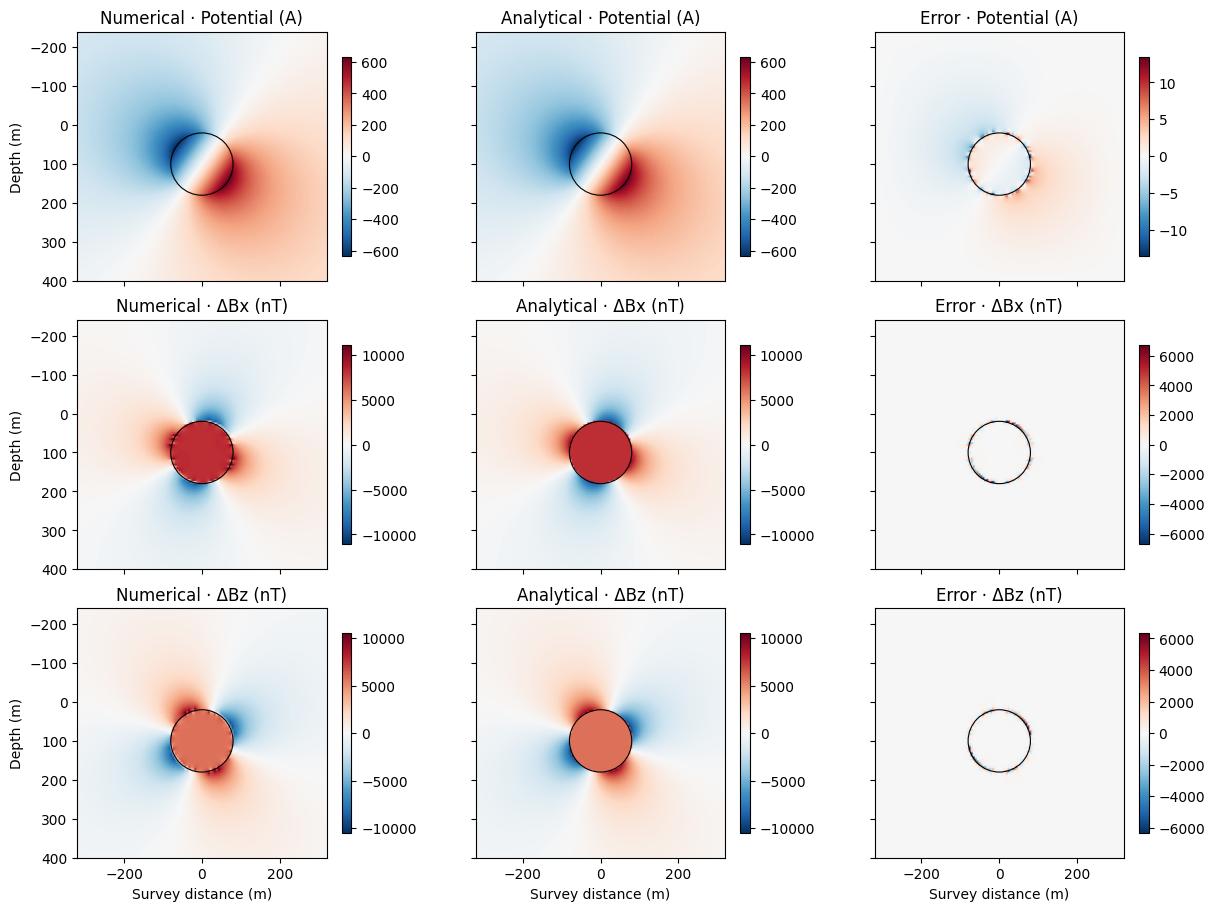

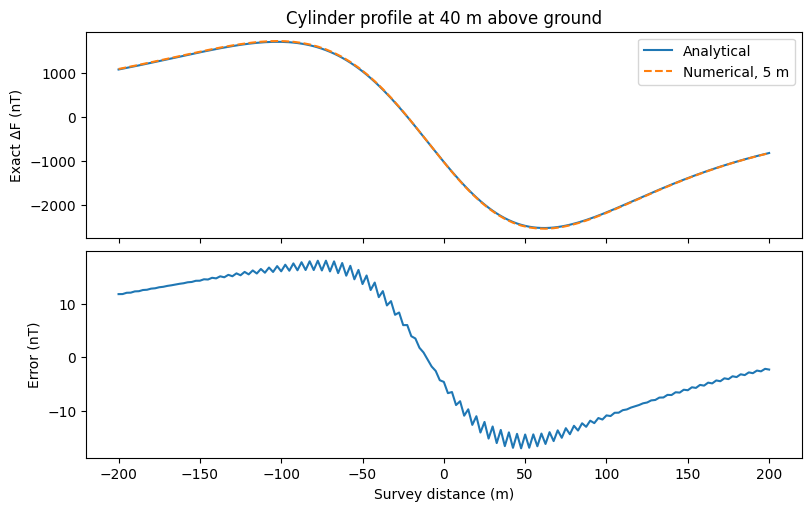

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9), layout="constrained",
                         sharex=True, sharey=True)
extent = [-320, 320, 400, -240]
for row, (name, numeric, analytic) in enumerate([
    ("Potential (A)", example["phi"], example["exact_phi"]),
    ("ΔBx (nT)", example["bx"], example["exact_b"][..., 0]),
    ("ΔBz (nT)", example["bz"], example["exact_b"][..., 1]),
]):
    limit = max(np.max(abs(numeric)), np.max(abs(analytic)))
    difference = numeric - analytic
    for col, (title, values, scale) in enumerate([
        ("Numerical", numeric, limit), ("Analytical", analytic, limit),
        ("Error", difference, np.max(abs(difference))),
    ]):
        ax = axes[row, col]
        mesh = ax.imshow(values, extent=extent, cmap="RdBu_r", vmin=-scale, vmax=scale)
        ax.add_patch(plt.Circle((0, CENTER_Z), RADIUS, fill=False, color="black", linewidth=0.8))
        ax.set_title(f"{title} · {name}")
        fig.colorbar(mesh, ax=ax, shrink=0.8)
        if col == 0:
            ax.set_ylabel("Depth (m)")
        if row == 2:
            ax.set_xlabel("Survey distance (m)")
plt.show()

fig, (ax, error_ax) = plt.subplots(2, sharex=True, figsize=(8, 5), layout="constrained")
ax.plot(LINE_X, example["exact_line"], label="Analytical")
ax.plot(LINE_X, example["line"], "--", label="Numerical, 5 m")
ax.set(ylabel="Exact ΔF (nT)", title="Cylinder profile at 40 m above ground")
ax.legend()
error_ax.plot(LINE_X, example["line"] - example["exact_line"])
error_ax.set(xlabel="Survey distance (m)", ylabel="Error (nT)")
plt.show()

## 4. Spatial grid refinement

Hold the physical cylinder, 640 m square domain, field, and line coordinates fixed. Transfer numerical profiles from each grid onto the same set of survey coordinates. A log-log fit over all four points provides an empirical slope $p$ in $E\propto h^p$. Also inspect individual refinement steps because rasterizing the circle can add or remove cells unevenly.

Spacing (m) | signed raster area error (%)
         20 |  3.451
         10 |  3.451
          5 |  0.964
        2.5 |  0.342

Quantity                     20 m       10 m        5 m      2.5 m    Fit p
Potential (A)              2.175%     2.091%     0.585%     0.226%     1.16
Bx inside (nT)             2.483%     0.943%     0.490%     0.282%     1.04
Bz inside (nT)             3.057%     0.958%     0.522%     0.319%     1.07
Bx outside (nT)            4.432%     3.372%     0.859%     0.305%     1.36
Bz outside (nT)            3.795%     3.249%     0.827%     0.298%     1.30
Profile (nT)               2.219%     2.836%     0.763%     0.264%     1.11


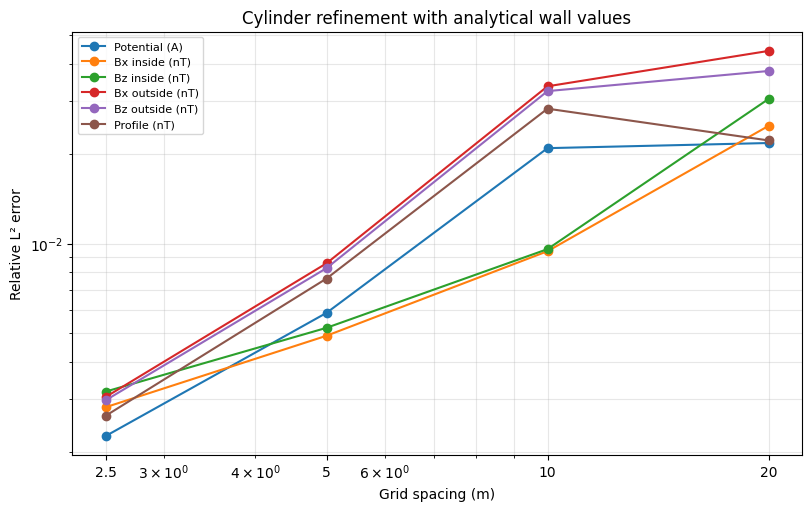

In [5]:
spacings = np.array([20, 10, 5, 2.5])
cases = [cylinder_case(h) if h != 5 else example for h in spacings]
print("Spacing (m) | signed raster area error (%)")
for h, case in zip(spacings, cases):
    print(f"{h:11g} | {100 * case['area_error']: .3f}")

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
print(f"\n{'Quantity':<22} {'20 m':>10} {'10 m':>10} {'5 m':>10} {'2.5 m':>10} {'Fit p':>8}")
for label in example["metrics"]:
    values = np.array([case["metrics"][label][1] for case in cases])
    slope = np.polyfit(np.log(spacings), np.log(values), 1)[0]
    label_values = " ".join(f"{value:10.3%}" for value in values)
    print(f"{label:<22} {label_values} {slope:8.2f}")
    ax.loglog(spacings, values, "o-", label=label)
ax.set(xlabel="Grid spacing (m)", ylabel="Relative L² error",
       title="Cylinder refinement with analytical wall values")
ax.set_xticks(spacings, labels=[f"{h:g}" for h in spacings])
ax.grid(which="both", alpha=0.3)
ax.legend(fontsize=8)
plt.show()

This test refines both the stencil and a cell-centered rasterization of the circular interface. Signed area error is informative but cannot capture the spatial arrangement of the misclassified cells. Field reconstruction differentiates the potential, so its error can be stronger near the jump even when the potential is close. An observed slope for these sampled grids is specific to the benchmark and is not a formal order for sharp interfaces.

In the executed study, the fitted slopes span 1.04–1.36. The profile error increases from 2.219% at 20 m to 2.836% at 10 m, then drops to 0.264% at 2.5 m. The 20 m and 10 m rasters have the same signed area error, yet their profile and field errors differ. This illustrates how the interface geometry and profile sampling can matter even when the area is unchanged.

## 5. Computational domain sensitivity

Reproduce the rectangular example using an 80 m wide, 40 m thick body with a top depth of 40 m and $\chi=0.1$. Use $F=50{,}000$ nT, $I=60^\circ$, $D=20^\circ$, and $A=0^\circ$. Sample the profile at 10 m height over the same 21 evenly spaced coordinates from −100 to 100 m.

First compare 5 m and 2.5 m cells in the 640 m square domain. Next keep 5 m cells and enlarge the square symmetrically about $x=z=0$. Every solve uses the application's zero-potential walls. Use the largest tested domain as a numerical reference. For this case, define acceptable agreement as at most 2 nT RMS and 4 nT maximum pointwise deviation relative to that reference. These are chosen study thresholds, not instrument specifications. Native timings and cell counts show the cost trend. Browser performance requires a separate measurement.

640 m domain, 5 m vs. 2.5 m grid: 0.36 nT RMS
640 m vs. 1280 m domain, fixed 5 m grid: 14.50 nT RMS

Side (m) |   cells | clearance (m) | RMS (nT) | max (nT) | native (s)
     640 |   16384 |           240 |   18.170 |   18.430 |      0.041
     960 |   36864 |           400 |    7.457 |    7.526 |      0.111
    1280 |   65536 |           560 |    3.669 |    3.697 |      0.255
    1600 |  102400 |           720 |    1.910 |    1.923 |      0.545
    1920 |  147456 |           880 |    0.953 |    0.959 |      0.979
    2560 |  262144 |          1200 |    0.000 |    0.000 |      2.164


**Accuracy-first default for this example:** a 1600 m square, with 720 m minimum clearance to the ore body. At 5 m use Grid(5, 320, 160, 160). This is the smallest tested setting meeting both thresholds. For browser use, benchmark this setting and validate any coarser preview independently.

10 m preview on 1600 m square: 25,600 cells, 2.241 nT RMS, 4.038 nT max, 0.070 s native. Meets both thresholds: False.


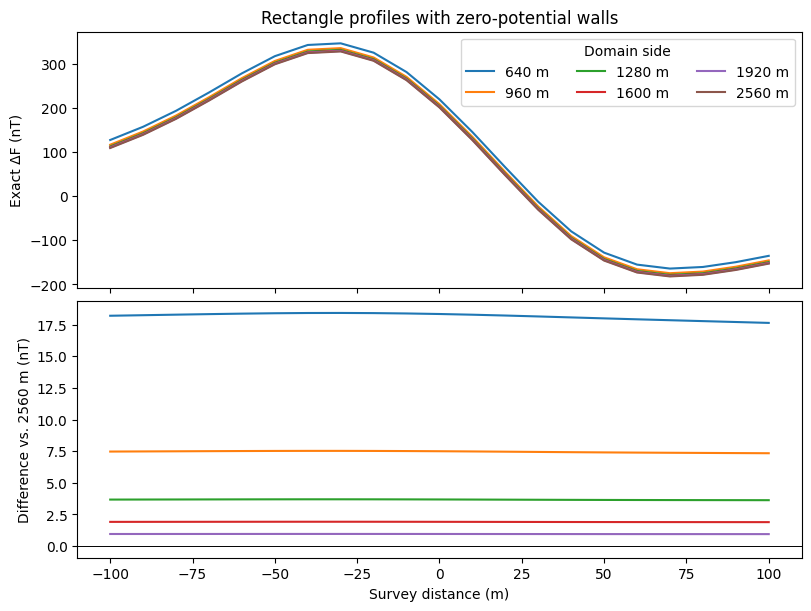

In [6]:
RECT_X = np.arange(-100, 101, 10)


def rectangle_profile(side_m, h):
    half_count = round(side_m / (2 * h))
    grid = Grid(h, 2 * half_count, half_count, half_count)
    start = perf_counter()
    result = simulate(OreBody(80, 40, 40, 0.1), grid=grid, intensity_nt=50_000,
                      inclination_deg=60, declination_deg=20, azimuth_deg=0,
                      observation_height_m=10)
    elapsed = perf_counter() - start
    return np.interp(RECT_X, result.x_m, result.profile_total_anomaly_nt), elapsed


sizes = [640, 960, 1280, 1600, 1920, 2560]
rectangles = {side: rectangle_profile(side, 5) for side in sizes}
fine_profile, _ = rectangle_profile(640, 2.5)
reference = rectangles[sizes[-1]][0]


def rms(values):
    return np.sqrt(np.mean(values**2))


grid_rms = rms(rectangles[640][0] - fine_profile)
doubling_rms = rms(rectangles[640][0] - rectangles[1280][0])
print(f"640 m domain, 5 m vs. 2.5 m grid: {grid_rms:.2f} nT RMS")
print(f"640 m vs. 1280 m domain, fixed 5 m grid: {doubling_rms:.2f} nT RMS\n")
print("Side (m) |   cells | clearance (m) | RMS (nT) | max (nT) | native (s)")
eligible = []
for side, (line, elapsed) in rectangles.items():
    difference = line - reference
    rms_error, peak_error = rms(difference), np.max(abs(difference))
    clearance = side / 2 - 80  # Bottom wall is closest to the body.
    print(f"{side:8} | {(side // 5)**2:7} | {clearance:13g} | "
          f"{rms_error:8.3f} | {peak_error:8.3f} | {elapsed:10.3f}")
    if side != sizes[-1] and rms_error <= 2 and peak_error <= 4:
        eligible.append(side)
if eligible:
    recommended = min(eligible)
    count = recommended // 5
    display(Markdown(
        f"**Accuracy-first default for this example:** a {recommended} m square, "
        f"with {recommended / 2 - 80:g} m minimum clearance to the ore body. "
        f"At 5 m use Grid(5, {count}, {count // 2}, {count // 2}). "
        "This is the smallest tested setting meeting both thresholds. For browser use, "
        "benchmark this setting and validate any coarser preview independently."
    ))
else:
    display(Markdown("No smaller domain met both thresholds. Extend the reference domain "
                     "before choosing an accuracy-first default."))

if eligible:
    preview, preview_seconds = rectangle_profile(recommended, 10)
    difference = preview - reference
    preview_rms, preview_peak = rms(difference), np.max(abs(difference))
    meets_target = preview_rms <= 2 and preview_peak <= 4
    print(f"10 m preview on {recommended} m square: {(recommended // 10)**2:,} cells, "
          f"{preview_rms:.3f} nT RMS, {preview_peak:.3f} nT max, "
          f"{preview_seconds:.3f} s native. Meets both thresholds: {meets_target}.")
    if meets_target:
        display(Markdown(
            "The 10 m grid is a candidate for the interactive default for this case. "
            "Use 5 m for a refinement check and revisit grid spacing for thinner bodies."
        ))

fig, (ax, error_ax) = plt.subplots(2, sharex=True, figsize=(8, 6), layout="constrained")
for side, (line, _) in rectangles.items():
    ax.plot(RECT_X, line, label=f"{side} m")
    if side != sizes[-1]:
        error_ax.plot(RECT_X, line - reference, label=f"{side} m")
ax.set(ylabel="Exact ΔF (nT)", title="Rectangle profiles with zero-potential walls")
ax.legend(title="Domain side", ncols=3)
error_ax.axhline(0, color="black", linewidth=0.7)
error_ax.set(xlabel="Survey distance (m)", ylabel="Difference vs. 2560 m (nT)")
plt.show()

## 6. Interpretation and limitations

The cylinder isolates errors from the numerical stencil, the stair-stepped interface, and field reconstruction by prescribing the exact potential at the outer boundary. A small algebraic residual shows that the assembled equations were solved accurately. It does not measure agreement with the continuous PDE. Potential errors may be smaller than field errors because gradients amplify short-scale variation, especially near an interface. The profile is computed in air, where the field is smooth, but also includes interpolation error. Compare the numerical and analytical panels using the shared color scales, then look at the separate error scales.

The rectangular study separates grid sensitivity from domain truncation. With zero-potential walls, increasing the padding changes the boundary approximation even at fixed cell spacing. Differences from the largest square are useful for selecting padding for this case but do not establish the absolute open-domain error. The recommended clearance depends on the model depth and width, contrast, field direction, observation line, and error budget. The measured native timings cannot establish latency or peak memory in a browser worker.

Infinite strike removes end effects. Finite ore bodies with significant variation along strike require a 3D model. Linear isotropic susceptibility assumes magnetization is proportional and parallel to the local field and omits saturation, anisotropy, and hysteresis. No remanent magnetization is included, so the model cannot interpret anomalies dominated by permanent magnetization. The uniform inducing field and unit-permeability host are local approximations.

### References

- Blakely, R. J. (1995), *Potential Theory in Gravity and Magnetic Applications*. [Cambridge University Press](https://doi.org/10.1017/CBO9780511549816)
- LeVeque, R. J. (2007), *Finite Difference Methods for Ordinary and Partial Differential Equations*. [SIAM](https://doi.org/10.1137/1.9780898717839)